In [1]:
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
enso_nao_flags = pd.read_csv('/home/kperny/VolMIP_stratosphere/tab/nao_enso_flags.csv')
enso_nao_flags = enso_nao_flags.set_index(['model', 'realization'])

In [18]:
path = "/sto4/data/Intermediate/VolMIP/pinatubo-full/"
models = ['CanESM5', 'GISS-E2-1-G','MPI-ESM1-2-LR', 'MIROC-ES2L', 'UKESM1-0-LL']
colors = ['darkmagenta', 'darkorange', 'royalblue', 'limegreen', 'deepskyblue']
plotdir = '/home/kperny/VolMIP_stratosphere/plots/'
precentage = 0.75

In [19]:
ds_ta = {} 
ds_ua = {} 
df = []
for model in models:
    ds_ta[model] = xr.open_dataset(path + model + '/ta_anomaly_' + model + '.nc')
    ds_ua[model] = xr.open_dataset(path + model + '/ua_anomaly_' + model + '.nc')

/tmp/ipykernel_1020873/2961818427.py:5: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds_ta[model] = xr.open_dataset(path + model + '/ta_anomaly_' + model + '.nc')
/tmp/ipykernel_1020873/2961818427.py:6: SerializationWarning: Unable to decode time axis into full numpy.datetime64[ns] objects, continuing using cftime.datetime objects instead, reason: dates out of range. To silence this warning use a coarser resolution 'time_unit' or specify 'use_cftime=True'.
  ds_ua[model] = xr.open_dataset(path + model + '/ua_anomaly_' + model + '.nc')


CanESM5
Ensemble member found: 0 for ENSO:-1 and NAO=-1
GISS-E2-1-G
MPI-ESM1-2-LR
MIROC-ES2L
Ensemble member found: 0 for ENSO:-1 and NAO=0
UKESM1-0-LL


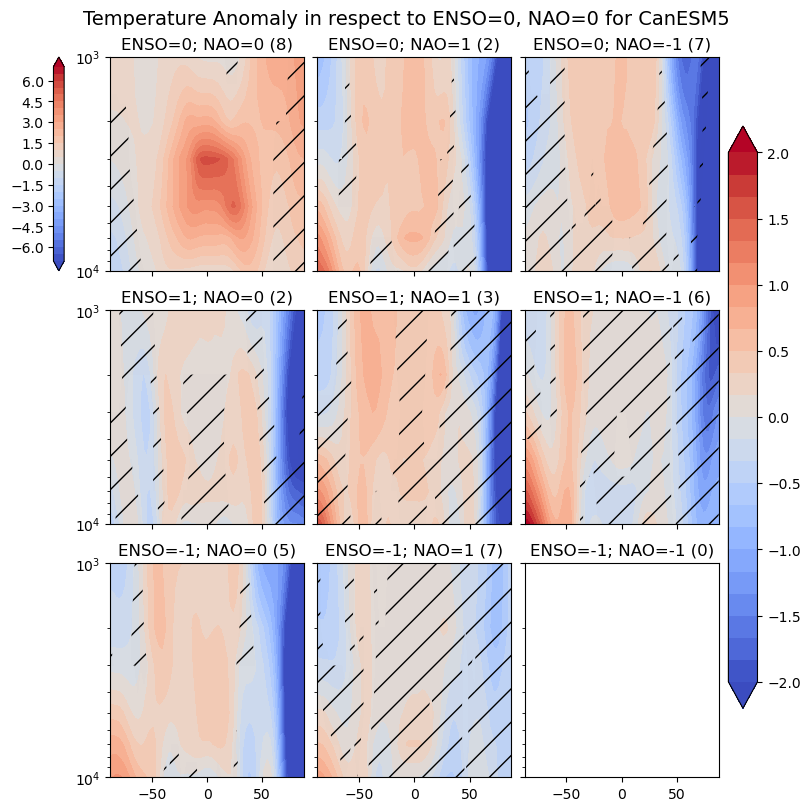

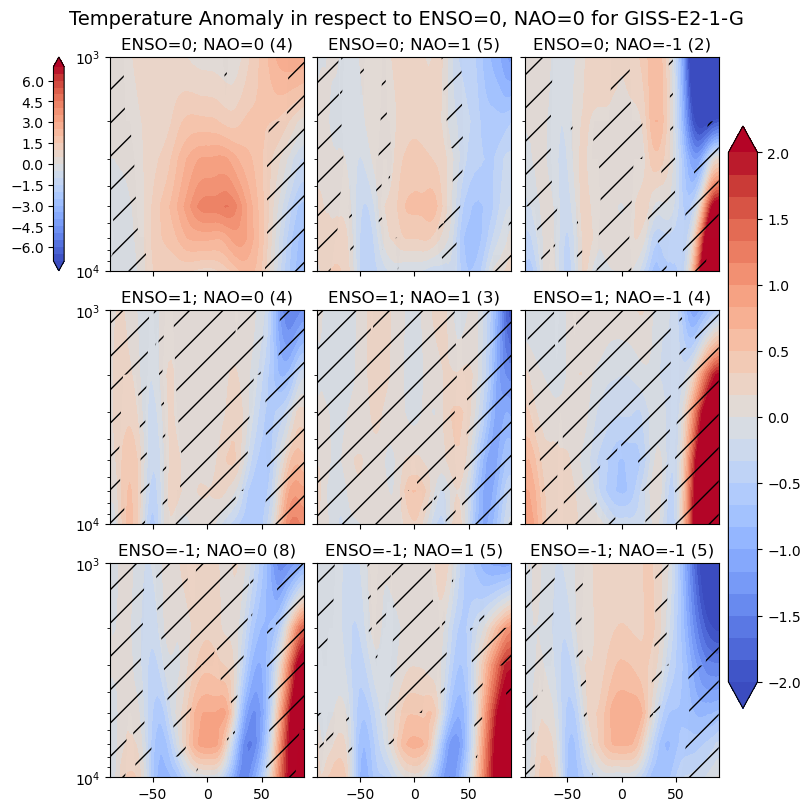

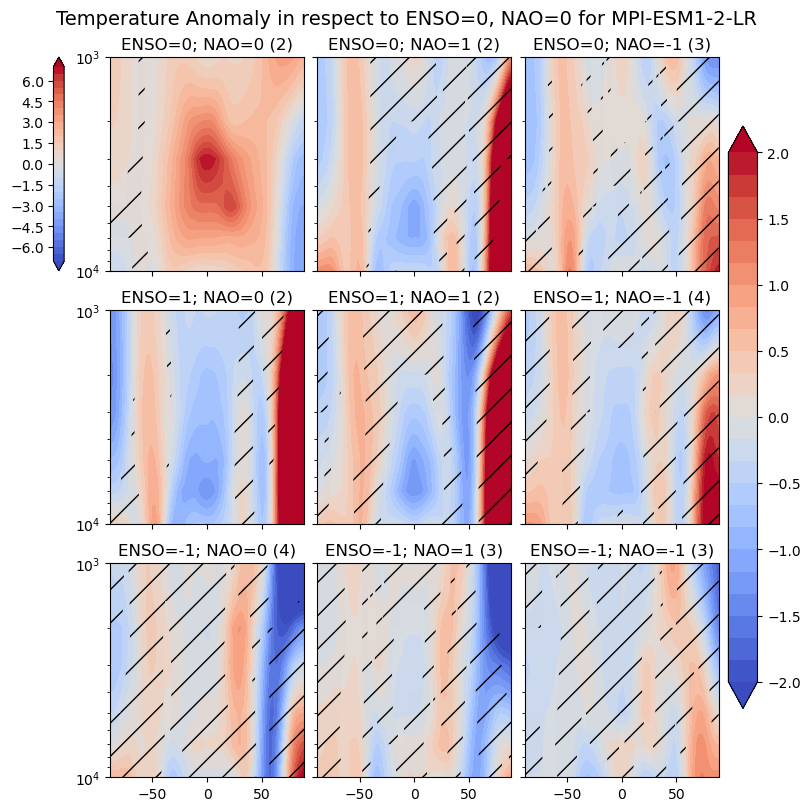

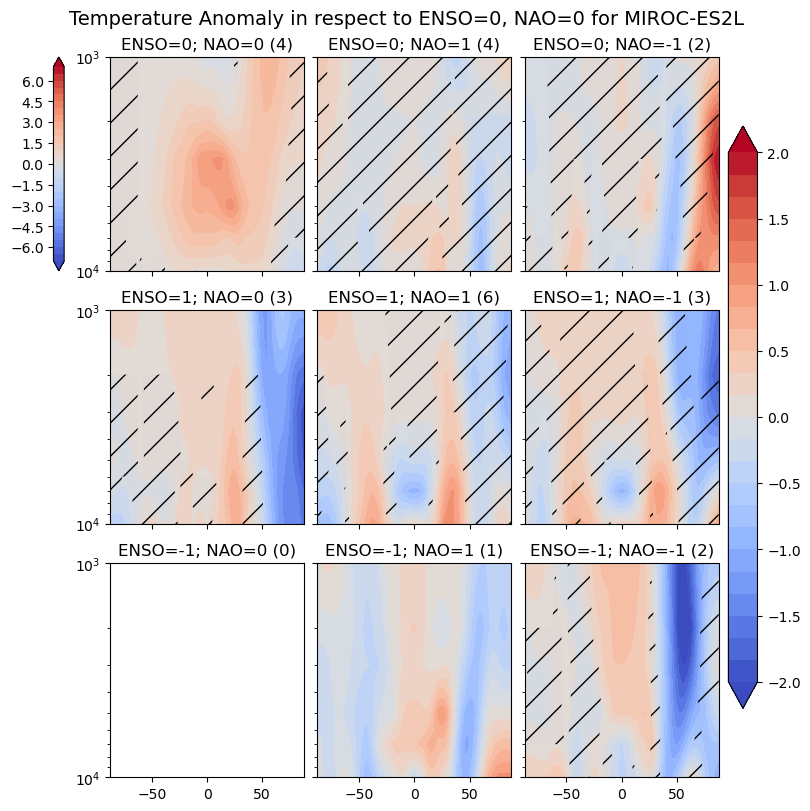

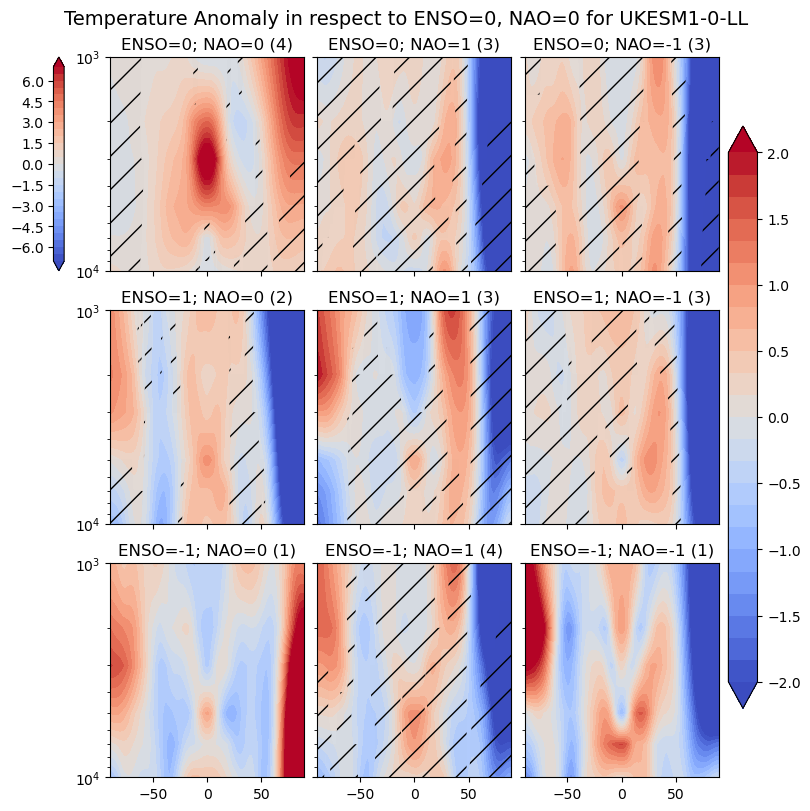

In [68]:
for model in models:
    print(model)
    tmp = ds_ta[model].ano.sel(time=slice('1991-12','1992-02'))


    fig, axs = plt.subplots(3,3, figsize=(8,8), layout='constrained', sharex=True, sharey=True)

    for i,enso in enumerate([0, 1, -1]):
        for j,nao in enumerate([0, 1, -1]):
            if (enso == 0) & (nao==0):
                ens = enso_nao_flags.where((enso_nao_flags['enso_flag']==enso) & (enso_nao_flags['nao_flag']==nao)).loc[model].dropna().index
                sign = int(len(ens) * precentage)
                mean = tmp.sel(ens=ens).mean(['ens', 'time']).squeeze()
                mean_sign = np.sign(mean)
                data_sign = np.sign((tmp.sel(ens=ens).mean('time')).squeeze())
                m = axs[i,j].contourf(mean.lat, mean.plev, mean, cmap='coolwarm', levels=np.linspace(-7,7,29), extend='both')
                axs[i,j].contourf(mean.lat, mean.plev, (data_sign == mean_sign).sum('ens'),[0, sign], cmap=plt.get_cmap("gray"), hatches=['/', None], alpha=0.01)
            else:
                ens = enso_nao_flags.where((enso_nao_flags['enso_flag']==enso) & (enso_nao_flags['nao_flag']==nao)).loc[model].dropna().index
                sign = int(len(ens) * precentage)
                
                try:
                    data_mean = (tmp.sel(ens=ens).mean(['ens', 'time']) - mean).squeeze()
                    p = axs[i,j].contourf(data_mean.lat, data_mean.plev, data_mean, cmap='coolwarm', levels=np.linspace(-2,2,25), extend='both')
                    
                    data = (tmp.sel(ens=ens).mean('time') - mean).squeeze()
                    data_sign = np.sign(data)
                    mean_sign = np.sign(data_mean)
                    axs[i,j].contourf(data_mean.lat, data_mean.plev, (data_sign == mean_sign).sum('ens'),[0, sign], cmap=plt.get_cmap("gray"), hatches=['/', None], alpha=0.01)
                except ValueError:
                    if len(ens)==1:
                        data_mean = (tmp.sel(ens=ens).mean(['ens', 'time']) - mean).squeeze()
                        p = axs[i,j].contourf(data_mean.lat, data_mean.plev, data_mean, cmap='coolwarm', levels=np.linspace(-2,2,25), extend='both')
                    else:
                        print('Ensemble member found: ' + str(len(ens)) + ' for ENSO:'+ str(enso) + ' and NAO=' + str(nao))
                
            axs[i,j].set_ylim(10000,1000)
            axs[i,j].set_yscale('log')
            axs[i,j].set_title('ENSO=' + str(enso) + '; NAO=' + str(nao) + ' (' + str(len(ens)) + ')')
    fig.colorbar(m, location='left')
    fig.colorbar(p, ax=axs[0:3, 2])
    fig.suptitle('Temperature Anomaly in respect to ENSO=0, NAO=0 for ' + str(model), fontsize=14)
    # plt.savefig(plotdir + 'poststamps_mean/ta_anomalyToNeutral_' + str(model) + '.png', dpi=200)
    plt.savefig(plotdir + 'poststamps_mean/ta_anomalyToNeutral_' + str(model) + '_sign.png', dpi=200)

In [95]:
np.linspace(-5,5,21)

array([-5. , -4.5, -4. , -3.5, -3. , -2.5, -2. , -1.5, -1. , -0.5,  0. ,
        0.5,  1. ,  1.5,  2. ,  2.5,  3. ,  3.5,  4. ,  4.5,  5. ])

CanESM5
Ensemble member found: 0 for ENSO:-1 and NAO=-1
GISS-E2-1-G
MPI-ESM1-2-LR
MIROC-ES2L
Ensemble member found: 0 for ENSO:-1 and NAO=0
UKESM1-0-LL


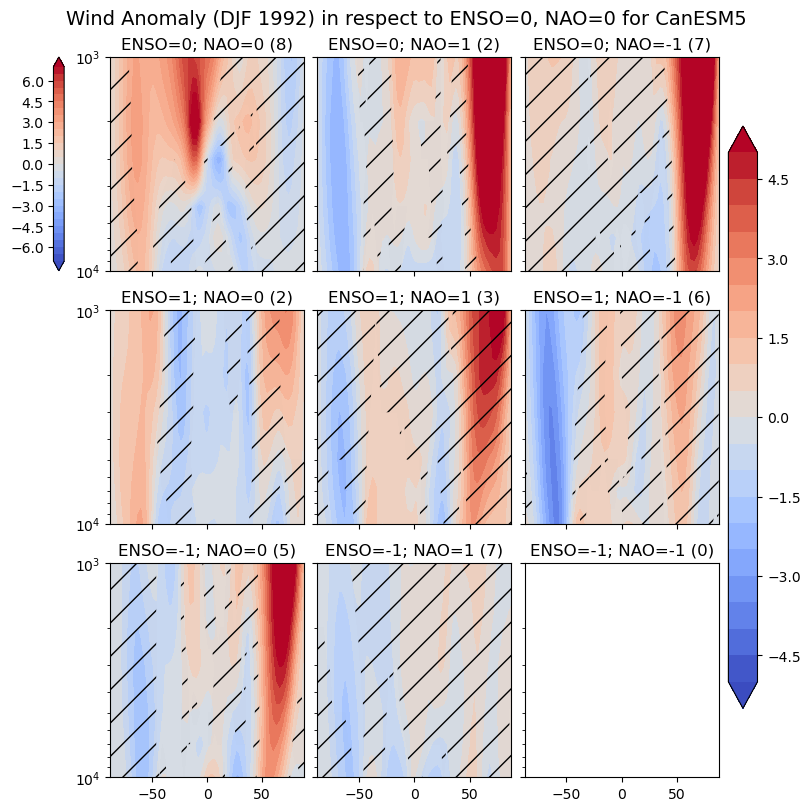

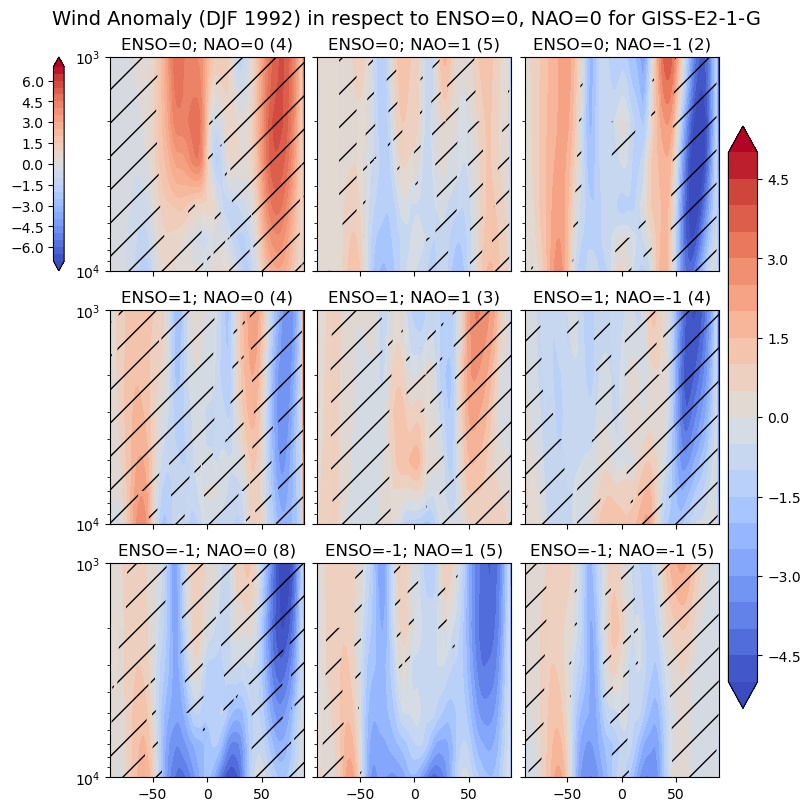

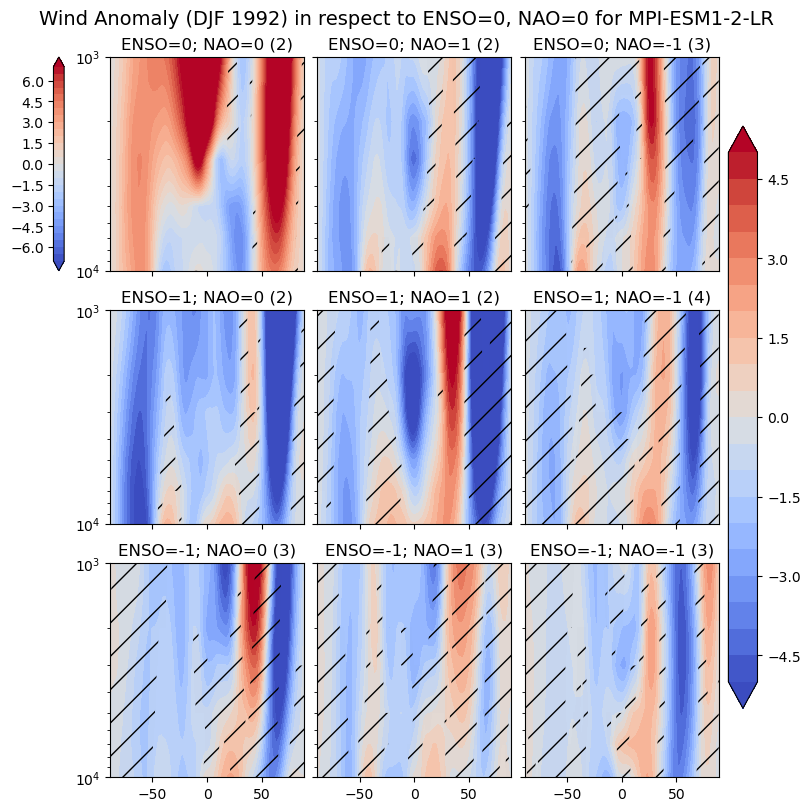

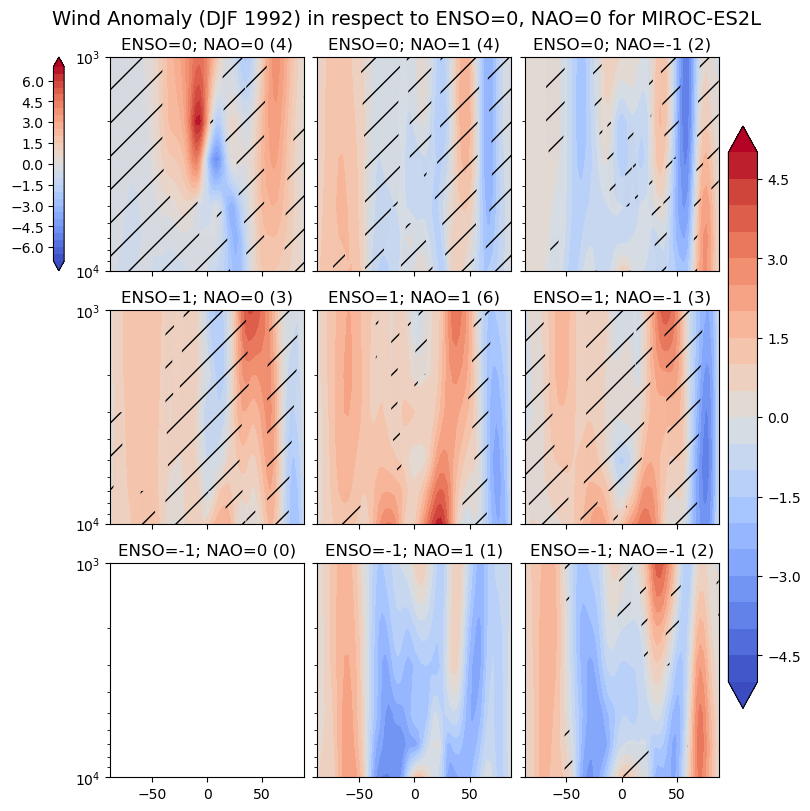

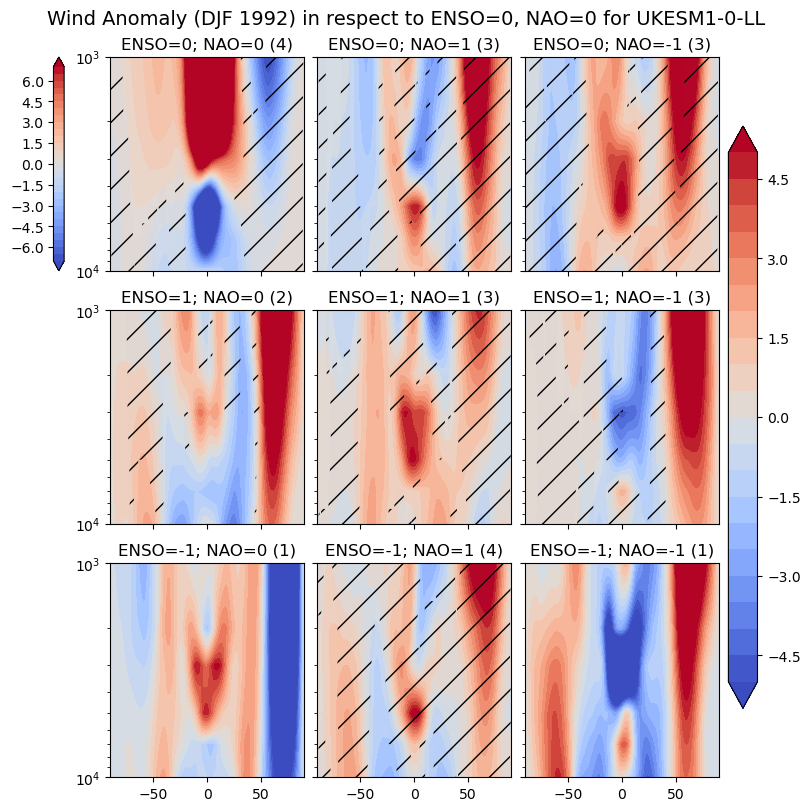

In [96]:
for model in models:
    print(model)
    tmp = ds_ua[model].ano.sel(time=slice('1991-12','1992-02'))


    fig, axs = plt.subplots(3,3, figsize=(8,8), layout='constrained', sharex=True, sharey=True)

    for i,enso in enumerate([0, 1, -1]):
        for j,nao in enumerate([0, 1, -1]):
            if (enso == 0) & (nao==0):
                ens = enso_nao_flags.where((enso_nao_flags['enso_flag']==enso) & (enso_nao_flags['nao_flag']==nao)).loc[model].dropna().index
                sign = int(len(ens) * precentage)
                mean = tmp.sel(ens=ens).mean(['ens', 'time']).squeeze()
                mean_sign = np.sign(mean)
                data_sign = np.sign((tmp.sel(ens=ens).mean('time')).squeeze())
                m = axs[i,j].contourf(mean.lat, mean.plev, mean, cmap='coolwarm', levels=np.linspace(-7,7,29), extend='both')
                axs[i,j].contourf(mean.lat, mean.plev, (data_sign == mean_sign).sum('ens'),[0, sign], cmap=plt.get_cmap("gray"), hatches=['/', None], alpha=0.01)
            else:
                try:
                    ens = enso_nao_flags.where((enso_nao_flags['enso_flag']==enso) & (enso_nao_flags['nao_flag']==nao)).loc[model].dropna().index
                    sign = int(len(ens) * precentage)
                    data_mean = (tmp.sel(ens=ens).mean(['ens', 'time']) - mean).squeeze()
                    p = axs[i,j].contourf(data_mean.lat, data_mean.plev, data_mean, cmap='coolwarm', levels=np.linspace(-5,5,21), extend='both')
                    
                    data = (tmp.sel(ens=ens).mean('time') - mean).squeeze()
                    data_sign = np.sign(data)
                    mean_sign = np.sign(data_mean)
                    axs[i,j].contourf(data_mean.lat, data_mean.plev, (data_sign == mean_sign).sum('ens'),[0, sign], cmap=plt.get_cmap("gray"), hatches=['/', None], alpha=0.01)
                except ValueError:
                    if len(ens)==1:
                        data_mean = (tmp.sel(ens=ens).mean(['ens', 'time']) - mean).squeeze()
                        p = axs[i,j].contourf(data_mean.lat, data_mean.plev, data_mean, cmap='coolwarm', levels=np.linspace(-5,5,21), extend='both')
                    else:
                        print('Ensemble member found: ' + str(len(ens)) + ' for ENSO:'+ str(enso) + ' and NAO=' + str(nao))
                except KeyError:
                    ens = ens.drop('r22i1p1f1')
                    sign = int(len(ens) * precentage)
                    data_mean = (tmp.sel(ens=ens).mean(['ens', 'time']) - mean).squeeze()
                    p = axs[i,j].contourf(data_mean.lat, data_mean.plev, data_mean, cmap='coolwarm', levels=np.linspace(-5,5,21), extend='both')
                    data = (tmp.sel(ens=ens).mean('time') - mean).squeeze()
                    data_sign = np.sign(data)
                    mean_sign = np.sign(data_mean)
                    axs[i,j].contourf(data_mean.lat, data_mean.plev, (data_sign == mean_sign).sum('ens'),[0, sign], cmap=plt.get_cmap("gray"), hatches=['/', None], alpha=0.01)
            axs[i,j].set_ylim(10000,1000)
            axs[i,j].set_yscale('log')
            axs[i,j].set_title('ENSO=' + str(enso) + '; NAO=' + str(nao) + ' (' + str(len(ens)) + ')')
    fig.colorbar(m, location='left')
    fig.colorbar(p, ax=axs[0:3, 2])
    fig.suptitle('Wind Anomaly (DJF 1992) in respect to ENSO=0, NAO=0 for ' + str(model), fontsize=14)
    # plt.savefig(plotdir + 'poststamps_mean/ua_anomalyToNeutral_' + str(model) + '.png', dpi=200)
    plt.savefig(plotdir + 'poststamps_mean/ua_anomalyToNeutral_' + str(model) + '_sign.png', dpi=200)

0


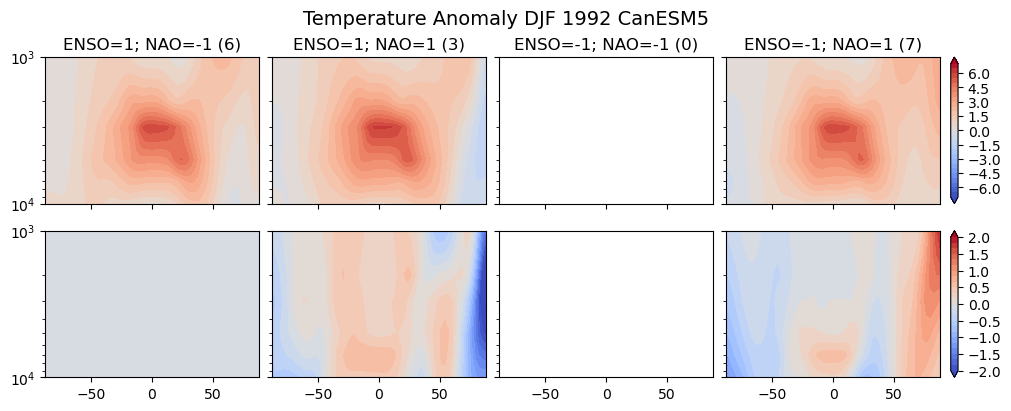

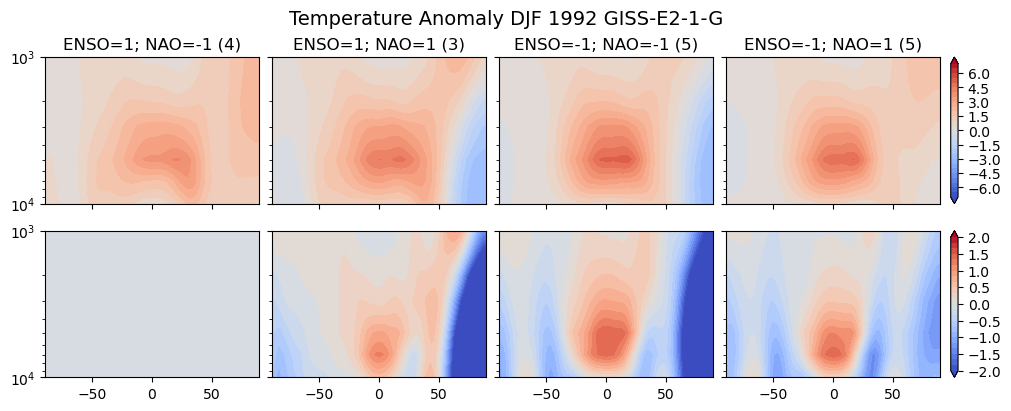

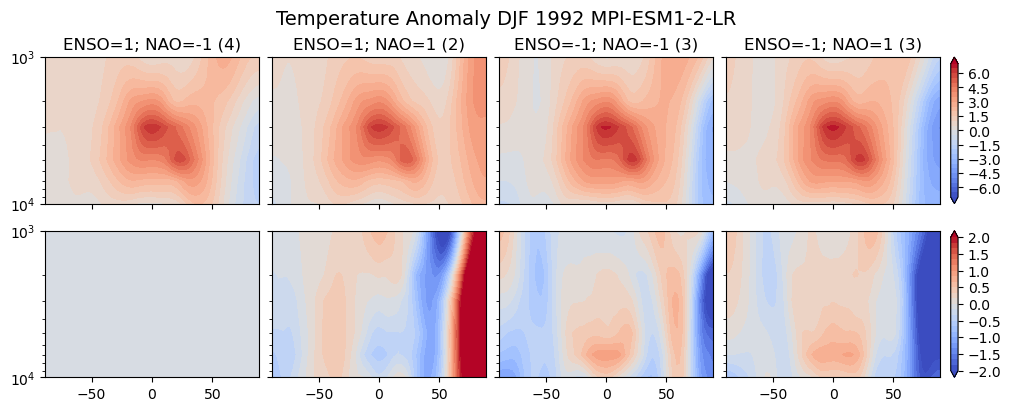

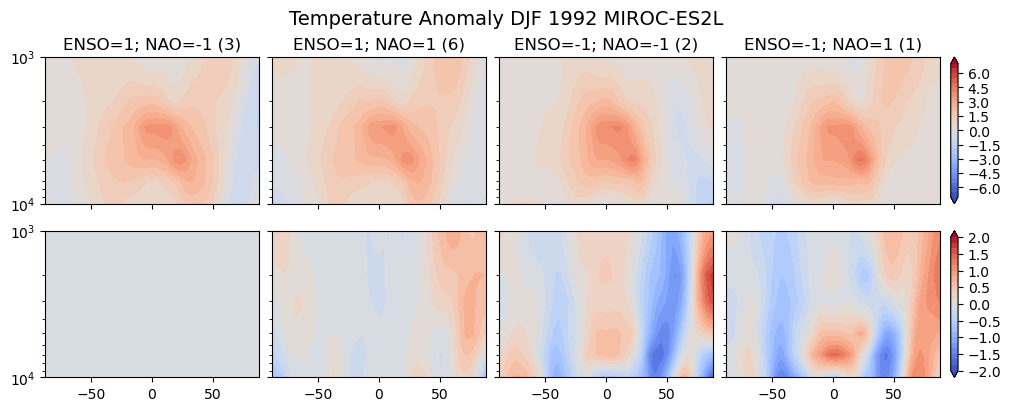

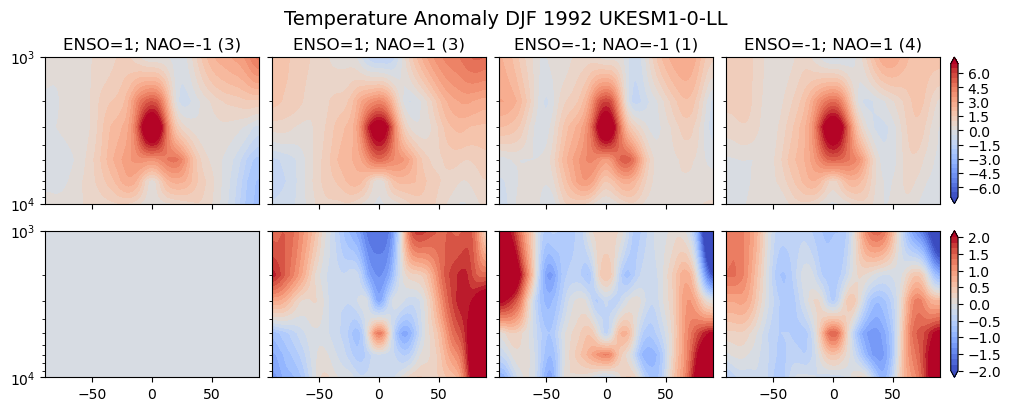

In [99]:
for model in models:
    tmp = ds_ta[model].ano.sel(time=slice('1991-12','1992-02'))

    fig, axs = plt.subplots(2,4, figsize=(10,4), layout='constrained', sharex=True, sharey=True)
    enso = [1,1,-1,-1]
    nao = [-1,1,-1,1]
    for i in range(4):
        if i==0:
            save = enso_nao_flags.where((enso_nao_flags['enso_flag']==enso[i]) & (enso_nao_flags['nao_flag']==nao[i])).loc[model].dropna().index
        ens = enso_nao_flags.where((enso_nao_flags['enso_flag']==enso[i]) & (enso_nao_flags['nao_flag']==nao[i])).loc[model].dropna().index
        sign = int(len(ens) * precentage)
                
        data = tmp.sel(ens=ens).mean(['ens', 'time']).squeeze()
        mean_sign = np.sign(data)
        data_sign = np.sign((tmp.sel(ens=ens).mean('time')).squeeze())
        diff_mean = data - tmp.sel(ens=save).mean(['ens', 'time']).squeeze()
        try:
            m = axs[0,i].contourf(data.lat, data.plev, data, cmap='coolwarm', levels=np.linspace(-7,7,29), extend='both')
            d = axs[1,i].contourf(data.lat, data.plev, data - tmp.sel(ens=save).mean(['ens', 'time']).squeeze(), cmap='coolwarm', levels=np.linspace(-2,2,25), extend='both')
            try:
                #axs[0,i].contourf(data.lat, data.plev, (data_sign == mean_sign).sum('ens'),[0, sign], cmap=plt.get_cmap("gray"), hatches=['/', None], alpha=0.01)
                data = (tmp.sel(ens=ens).mean('time') - tmp.sel(ens=save).mean(['ens', 'time'])).squeeze()
                data_sign = np.sign(data)
                mean_sign = np.sign(diff_mean)
                #axs[1,i].contourf(data.lat, data.plev, (data_sign == mean_sign).sum('ens'),[0, sign], cmap=plt.get_cmap("gray"), hatches=['/', None], alpha=0.01)
            except:
                print('Significance: ' + str(len(ens)))
        except:
            print(len(ens))

        axs[0,i].set_ylim(10000,1000)
        axs[0,i].set_yscale('log')
        axs[0,i].set_title('ENSO=' + str(enso[i]) + '; NAO=' + str(nao[i]) + ' (' + str(len(ens)) + ')')
        axs[1,i].set_ylim(10000,1000)
        axs[1,i].set_yscale('log')

    fig.colorbar(m)
    fig.colorbar(d)
    fig.suptitle('Temperature Anomaly DJF 1992 ' + model, fontsize=14)
    plt.savefig(plotdir + '/poststamps_mean/ta_anomaly_meanAndDiff_' + model + '.png', dpi=200)

0
Significance: 1
Significance: 1


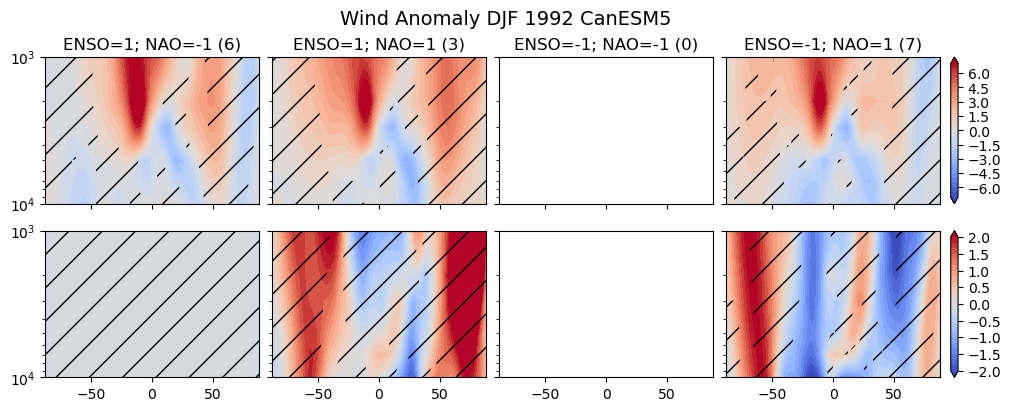

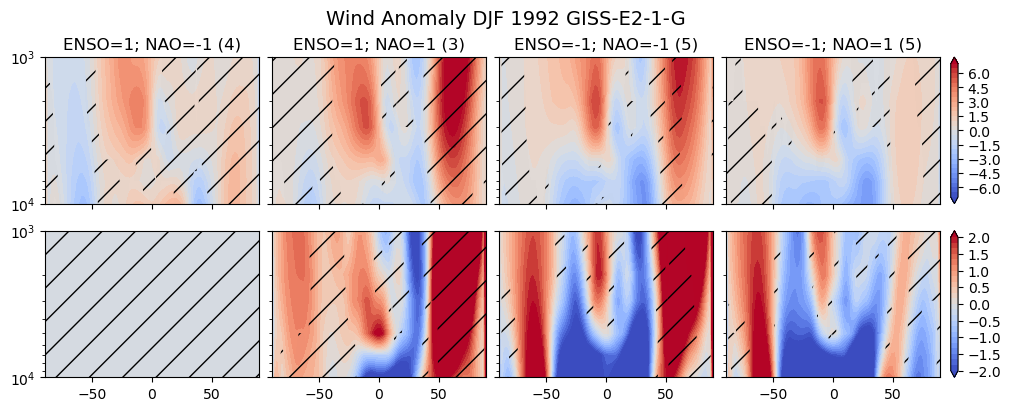

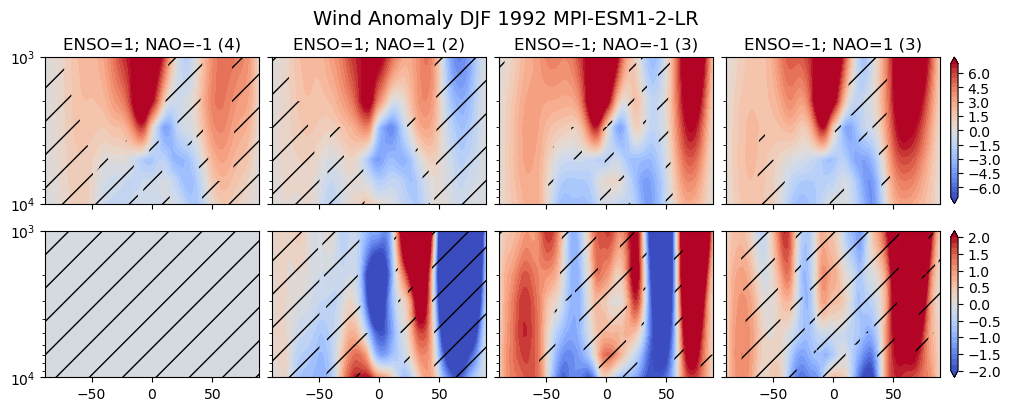

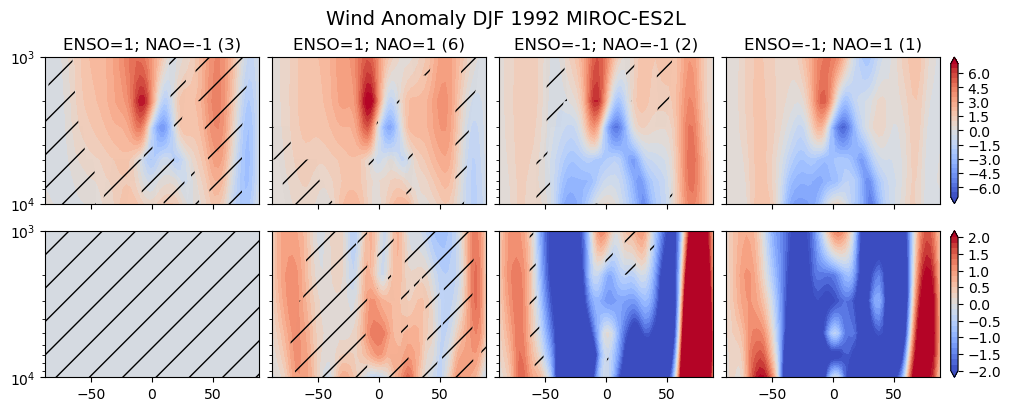

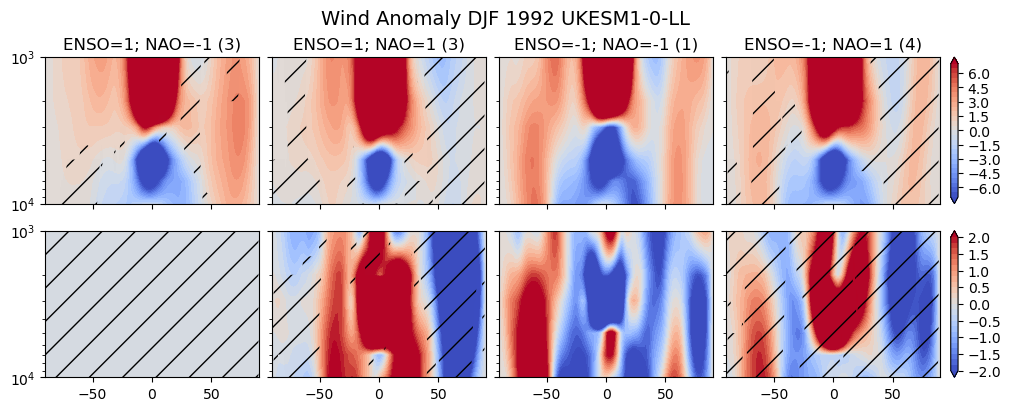

In [101]:
for model in models:
    tmp = ds_ua[model].ano.sel(time=slice('1991-12','1992-02'))

    fig, axs = plt.subplots(2,4, figsize=(10,4), layout='constrained', sharex=True, sharey=True)
    enso = [1,1,-1,-1]
    nao = [-1,1,-1,1]
    for i in range(4):
        if i==0:
            save = enso_nao_flags.where((enso_nao_flags['enso_flag']==enso[i]) & (enso_nao_flags['nao_flag']==nao[i])).loc[model].dropna().index
        ens = enso_nao_flags.where((enso_nao_flags['enso_flag']==enso[i]) & (enso_nao_flags['nao_flag']==nao[i])).loc[model].dropna().index
        sign = int(len(ens) * precentage)
                
        data = tmp.sel(ens=ens).mean(['ens', 'time']).squeeze()
        mean_sign = np.sign(data)
        data_sign = np.sign((tmp.sel(ens=ens).mean('time')).squeeze())
        diff_mean = data - tmp.sel(ens=save).mean(['ens', 'time']).squeeze()
        try:
            m = axs[0,i].contourf(data.lat, data.plev, data, cmap='coolwarm', levels=np.linspace(-7,7,29), extend='both')
            d = axs[1,i].contourf(data.lat, data.plev, data - tmp.sel(ens=save).mean(['ens', 'time']).squeeze(), cmap='coolwarm', levels=np.linspace(-2,2,25), extend='both')
            try:
                axs[0,i].contourf(data.lat, data.plev, (data_sign == mean_sign).sum('ens'),[0, sign], cmap=plt.get_cmap("gray"), hatches=['/', None], alpha=0.01)
                data = (tmp.sel(ens=ens).mean('time') - tmp.sel(ens=save).mean(['ens', 'time'])).squeeze()
                data_sign = np.sign(data)
                mean_sign = np.sign(diff_mean)
                axs[1,i].contourf(data.lat, data.plev, (data_sign == mean_sign).sum('ens'),[0, sign], cmap=plt.get_cmap("gray"), hatches=['/', None], alpha=0.01)
            except:
                print('Significance: ' + str(len(ens)))
        except:
            print(len(ens))

        axs[0,i].set_ylim(10000,1000)
        axs[0,i].set_yscale('log')
        axs[0,i].set_title('ENSO=' + str(enso[i]) + '; NAO=' + str(nao[i]) + ' (' + str(len(ens)) + ')')
        axs[1,i].set_ylim(10000,1000)
        axs[1,i].set_yscale('log')

    fig.colorbar(m)
    fig.colorbar(d)
    fig.suptitle('Wind Anomaly DJF 1992 ' + model, fontsize=14)
    plt.savefig(plotdir + '/poststamps_mean/ua_anomaly_meanAndDiff_' + model + '.png', dpi=200)

# OLD

In [ ]:
ds_ta = {} 
ds_ua = {} 
df = []
for model in models:
    ds_ta[model] = xr.open_dataset(path + model + '/ta_anomaly_' + model + '.nc')
    ds_ua[model] = xr.open_dataset(path + model + '/ua_anomanxwqqrly_' + model + '.nc')
    tmp = ds_ta[model].sel(time=slice('1991-12', '1992-02')).mean('time').ano.to_dataframe()
    tmp = tmp.reset_index().drop('lon', axis=1)
    tmp['model'] = model
    df.append(tmp)

In [ ]:
df_models = pd.concat(df)
df_models = df_models.set_index(['model','ens'])

In [ ]:
fig, axs = plt.subplots(2,5, figsize=(15,8), layout='constrained', sharey=True)

for i, model in enumerate(models):
    tmp = ds_ta[model].ano.sel(time=slice('1991-12','1992-02')).mean(['time', 'ens'])
    tmp_ua = ds_ua[model].ano.sel(time=slice('1991-12','1992-02')).mean(['time', 'ens'])

    p = axs[0,i].contourf(tmp.lat, tmp.plev, tmp.squeeze(), cmap='coolwarm', levels=np.linspace(-7,7,29), extend='both')
    d = axs[1,i].contourf(tmp_ua.lat, tmp_ua.plev, tmp_ua.squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')

    axs[0,i].set_ylim(10000, 1000)
    axs[0,i].set_yscale('log')
    axs[0,i].set_title(model)

cbar = fig.colorbar(p, ax=axs[0:1,4], orientation='vertical')
cbar = fig.colorbar(d, ax=axs[1:2,4], orientation='vertical')
plt.suptitle('Temperature Anomaly DJF 1991/92', fontsize=14)
plt.savefig(plotdir + 'zonal_DJF_ta_ua.png', dpi=200)

In [ ]:
fig, axs = plt.subplots(2,5, figsize=(15,8), layout='constrained', sharey=True)

for i, model in enumerate(models):
    tmp = ds_ta[model].ano.sel(time=slice('1992-06','1992-08')).mean(['time', 'ens'])
    tmp_ua = ds_ua[model].ano.sel(time=slice('1992-06','1992-08')).mean(['time', 'ens'])

    p = axs[0,i].contourf(tmp.lat, tmp.plev, tmp.squeeze(), cmap='coolwarm', levels=np.linspace(-7,7,29), extend='both')
    d = axs[1,i].contourf(tmp_ua.lat, tmp_ua.plev, tmp_ua.squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')

    axs[0,i].set_ylim(10000, 1000)
    axs[0,i].set_yscale('log')
    axs[0,i].set_title(model)

cbar = fig.colorbar(p, ax=axs[0:1,4], orientation='vertical')
cbar = fig.colorbar(d, ax=axs[1:2,4], orientation='vertical')
plt.suptitle('Temperature Anomaly JJA 1992', fontsize=14)
plt.savefig(plotdir + 'zonal_JJA_ta_ua.png', dpi=200)

In [ ]:
# NAO and ENSO flags
fig, axs = plt.subplots(5,7, figsize=(13,8), layout='constrained', sharey=True, sharex=True)

indexes = [-1,0,1,-1,0,1]
flags = ['nao_flag','nao_flag','nao_flag','enso_flag','enso_flag','enso_flag']
names = ['NAO-', 'NAO0', 'NAO+', 'ENSO-', 'ENSO0', 'ENSO+']

for i, model in enumerate(models):
    tmp = ds_ta[model].ano.sel(time=slice('1991-12','1992-02'))
    all = tmp.mean(['time', 'ens'])
    p = axs[i,0].contourf(all.lat, all.plev, all.squeeze(), cmap='coolwarm', levels=np.linspace(-6,6,25), extend='both')

    for j in range(6):
         flag = enso_nao_flags.where(enso_nao_flags[flags[j]]==indexes[j]).loc[model].dropna().index
         axs[i,j+1].contourf(tmp.lat, tmp.plev, tmp.sel(ens=flag).mean(['time', 'ens']).squeeze(), cmap='coolwarm', levels=np.linspace(-6,6,25), extend='both')
         axs[0,j+1].set_title(names[j])
    axs[i,0].set_ylim(10000, 1000)
    axs[i,0].set_yscale('log')
    axs[i,0].set_ylabel(model)
    axs[0,0].set_title('all')

cbar = fig.colorbar(p, ax=axs[0:5,6], orientation='vertical')
plt.suptitle('Temperature Anomaly DJF 1992', fontsize=14)
plt.savefig(plotdir + 'zonal_DJF_ta_enso_nao.png', dpi=200)

In [ ]:
# NAO and ENSO flags
fig, axs = plt.subplots(5,7, figsize=(13,8), layout='constrained', sharey=True, sharex=True)

indexes = [-1,0,1,-1,0,1]
flags = ['nao_flag','nao_flag','nao_flag','enso_flag','enso_flag','enso_flag']
names = ['NAO-', 'NAO0', 'NAO+', 'ENSO-', 'ENSO0', 'ENSO+']

for i, model in enumerate(models):
    tmp = ds_ta[model].ano.sel(time=slice('1992-06','1992-08'))
    all = tmp.mean(['time', 'ens'])
    p = axs[i,0].contourf(all.lat, all.plev, all.squeeze(), cmap='coolwarm', levels=np.linspace(-6,6,25), extend='both')

    for j in range(6):
         flag = enso_nao_flags.where(enso_nao_flags[flags[j]]==indexes[j]).loc[model].dropna().index
         axs[i,j+1].contourf(tmp.lat, tmp.plev, tmp.sel(ens=flag).mean(['time', 'ens']).squeeze(), cmap='coolwarm', levels=np.linspace(-6,6,25), extend='both')
         axs[0,j+1].set_title(names[j])
    axs[i,0].set_ylim(10000, 1000)
    axs[i,0].set_yscale('log')
    axs[i,0].set_ylabel(model)
    axs[0,0].set_title('all')

cbar = fig.colorbar(p, ax=axs[0:5,6], orientation='vertical')
plt.suptitle('Temperature Anomaly JJA 1992', fontsize=14)
plt.savefig(plotdir + 'zonal_JJA_ta_enso_nao.png', dpi=200)

In [ ]:
# NAO and ENSO flags
fig, axs = plt.subplots(5,7, figsize=(13,8), layout='constrained', sharey=True, sharex=True)

indexes = [-1,0,1,-1,0,1]
flags = ['nao_flag','nao_flag','nao_flag','enso_flag','enso_flag','enso_flag']
names = ['NAO-', 'NAO0', 'NAO+', 'ENSO-', 'ENSO0', 'ENSO+']

for i, model in enumerate(models):
    tmp = ds_ua[model].ano.sel(time=slice('1991-12','1992-02'))

    all = tmp.mean(['time', 'ens'])
    p = axs[i,0].contourf(all.lat, all.plev, all.squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')

    for j in range(6):
        flag = enso_nao_flags.where(enso_nao_flags[flags[j]]==indexes[j]).loc[model].dropna().index
        try:
            axs[i,j+1].contourf(tmp.lat, tmp.plev, tmp.sel(ens=flag).mean(['time', 'ens']).squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')
        except KeyError:
            axs[i,j+1].contourf(tmp.lat, tmp.plev, tmp.sel(ens=tmp.ens[tmp.ens.isin(flag)]).mean(['time', 'ens']).squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')
            print(set(tmp.ens[tmp.ens.isin(flag)].values) - set(flag))
        axs[0,j+1].set_title(names[j])
    axs[i,0].set_ylim(10000, 1000)
    axs[i,0].set_yscale('log')
    axs[i,0].set_ylabel(model)
    axs[0,0].set_title('all')

cbar = fig.colorbar(p, ax=axs[0:5,6], orientation='vertical')
plt.suptitle('Wind Anomaly DJF 1992', fontsize=14)
plt.savefig(plotdir + 'zonal_DJF_ua_enso_nao.png', dpi=200)

In [ ]:
# NAO and ENSO flags
fig, axs = plt.subplots(5,7, figsize=(13,8), layout='constrained', sharey=True, sharex=True)

indexes = [-1,0,1,-1,0,1]
flags = ['nao_flag','nao_flag','nao_flag','enso_flag','enso_flag','enso_flag']
names = ['NAO-', 'NAO0', 'NAO+', 'ENSO-', 'ENSO0', 'ENSO+']

for i, model in enumerate(models):
    tmp = ds_ua[model].ano.sel(time=slice('1992-06','1992-08'))

    all = tmp.mean(['time', 'ens'])
    p = axs[i,0].contourf(all.lat, all.plev, all.squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')

    for j in range(6):
        flag = enso_nao_flags.where(enso_nao_flags[flags[j]]==indexes[j]).loc[model].dropna().index
        try:
            axs[i,j+1].contourf(tmp.lat, tmp.plev, tmp.sel(ens=flag).mean(['time', 'ens']).squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')
        except KeyError:
            axs[i,j+1].contourf(tmp.lat, tmp.plev, tmp.sel(ens=tmp.ens[tmp.ens.isin(flag)]).mean(['time', 'ens']).squeeze(), cmap='coolwarm', levels=np.linspace(-10,10,21), extend='both')
            print(set(tmp.ens[tmp.ens.isin(flag)].values) - set(flag))
        axs[0,j+1].set_title(names[j])
    axs[i,0].set_ylim(10000, 1000)
    axs[i,0].set_yscale('log')
    axs[i,0].set_ylabel(model)
    axs[0,0].set_title('all')

cbar = fig.colorbar(p, ax=axs[0:5,6], orientation='vertical')
plt.suptitle('Wind Anomaly JJA 1992', fontsize=14)
plt.savefig(plotdir + 'zonal_JJA_ua_enso_nao.png', dpi=200)